In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow.keras as keras
import utils

# DATASET

### MNIST

TRAIN SET shape: (60000, 28, 28)
TEST SET shape: (10000, 28, 28)


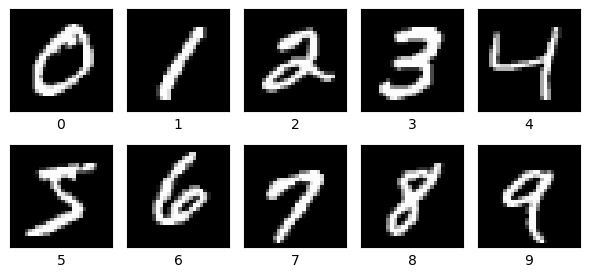

In [13]:
ds = keras.datasets.mnist
(train_images, train_labels), (test_images, test_labels) = ds.load_data()

class_names = ['0','1','2','3','4','5','6','7','8','9']

train_images = train_images/255.
test_images = test_images/255.

print(f"TRAIN SET shape: {train_images.shape}")
print(f"TEST SET shape: {test_images.shape}")

plt.figure(figsize=(6, 3))
for c in range(len(class_names)):
    idx = (train_labels == c).nonzero()[0][0].item()
    img, label = train_images[idx], train_labels[idx]
    plt.subplot(2, 5, c + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img.squeeze(), cmap="gray")
    plt.xlabel(label)
plt.tight_layout()
plt.ion()
plt.show()

### FASHION_MNIST

TRAIN SET shape: (60000, 28, 28)
TEST SET shape: (10000, 28, 28)


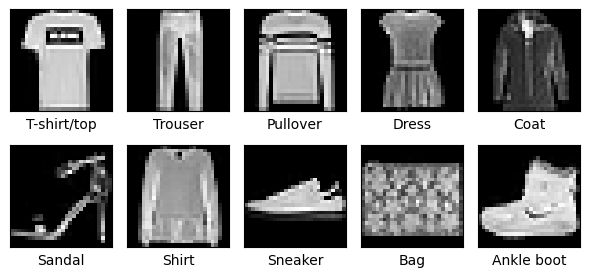

In [16]:
ds = keras.datasets.fashion_mnist
(train_images, train_labels), (test_images, test_labels) = ds.load_data()

class_names = [ 'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

train_images = train_images/255.
test_images = test_images/255.

print(f"TRAIN SET shape: {train_images.shape}")
print(f"TEST SET shape: {test_images.shape}")

plt.figure(figsize=(6, 3))
for c in range(len(class_names)):
    idx = (train_labels == c).nonzero()[0][0].item()
    img, label = train_images[idx], class_names[train_labels[idx]]
    plt.subplot(2, 5, c + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img.squeeze(), cmap="gray")
    plt.xlabel(label)
plt.tight_layout()
plt.ion()
plt.show()

## PARAM DEFINITION 

In [4]:
EPOCHS = 20
VERBOSE = 1

## MODEL 1x16

### CREATION

In [5]:
model_1x16 = keras.Sequential() # LINEAR STACK OF LAYER
model_1x16.add(keras.Input(shape=(28,28)))
model_1x16.add(keras.layers.Flatten())

#kernel_initializer = keras.initializers.RandomNormal(seed=np.random.randint(20)+1)
#kernel_initializer = keras.initializers.RandomUniform(seed=np.random.randint(20)+1)
kernel_initializer = keras.initializers.glorot_uniform(seed=np.random.randint(20)+1)

layer1 = keras.layers.Dense(16, activation='relu', kernel_initializer=kernel_initializer)
print("LAYER1 CONFIGURATION:")
print(layer1.get_config())

model_1x16.add(layer1)
model_1x16.add(keras.layers.Dense(10, activation='softmax', kernel_initializer=kernel_initializer))


model_1x16.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model_1x16.summary()

LAYER1 CONFIGURATION:
{'name': 'dense', 'trainable': True, 'dtype': 'float32', 'units': 16, 'activation': 'relu', 'use_bias': True, 'kernel_initializer': {'class_name': 'GlorotUniform', 'config': {'seed': 16}}, 'bias_initializer': {'class_name': 'Zeros', 'config': {}}, 'kernel_regularizer': {'class_name': 'L1', 'config': {'l1': 0.0010000000474974513}}, 'bias_regularizer': None, 'activity_regularizer': None, 'kernel_constraint': None, 'bias_constraint': None}
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 784)               0         
                                                                 
 dense (Dense)               (None, 16)                12560     
                                                                 
 dense_1 (Dense)             (None, 10)                170       
                                                       

### TRAINING

Epoch 1/20
1875/1875 [==============================] - 12s 5ms/step - loss: 0.9632 - accuracy: 0.7876 - val_loss: 0.8268 - val_accuracy: 0.7992
Epoch 2/20
1875/1875 [==============================] - 10s 6ms/step - loss: 0.7738 - accuracy: 0.8177 - val_loss: 0.7682 - val_accuracy: 0.8110
Epoch 3/20
1875/1875 [==============================] - 11s 6ms/step - loss: 0.7391 - accuracy: 0.8226 - val_loss: 0.7336 - val_accuracy: 0.8185
Epoch 4/20
1875/1875 [==============================] - 11s 6ms/step - loss: 0.7215 - accuracy: 0.8253 - val_loss: 0.7350 - val_accuracy: 0.8159
Epoch 5/20
1875/1875 [==============================] - 12s 6ms/step - loss: 0.7106 - accuracy: 0.8276 - val_loss: 0.7289 - val_accuracy: 0.8181
Epoch 6/20
1875/1875 [==============================] - 11s 6ms/step - loss: 0.7042 - accuracy: 0.8289 - val_loss: 0.7297 - val_accuracy: 0.8228
Epoch 7/20
1875/1875 [==============================] - 11s 6ms/step - loss: 0.6970 - accuracy: 0.8292 - val_loss: 0.7093 - val_ac

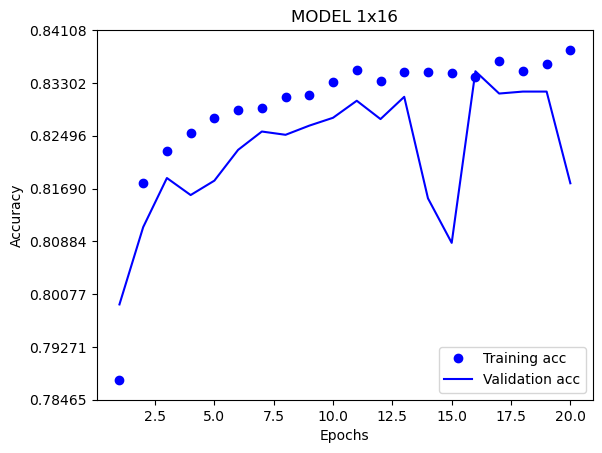

In [6]:
filename = "model_1x16.weights.h5"
history = model_1x16.fit(train_images, train_labels, epochs=EPOCHS, verbose=VERBOSE, validation_data = (test_images, test_labels))
history_dict = history.history
utils.hist_plot(history_dict, "MODEL 1x16")
#model_1x16.save_weights(filename)

## MODEL 4x16

### CREATION

In [7]:
model_4x16 = keras.Sequential([
    keras.Input(shape=(28,28)),
    keras.layers.Flatten(),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

model_4x16.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model_4x16.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_1 (Flatten)         (None, 784)               0         
                                                                 
 dense_2 (Dense)             (None, 16)                12560     
                                                                 
 dense_3 (Dense)             (None, 16)                272       
                                                                 
 dense_4 (Dense)             (None, 16)                272       
                                                                 
 dense_5 (Dense)             (None, 16)                272       
                                                                 
 dense_6 (Dense)             (None, 10)                170       
                                                                 
Total params: 13,546
Trainable params: 13,546
Non-trai

### TRAINING

Epoch 1/20
1875/1875 [==============================] - 15s 8ms/step - loss: 0.6795 - accuracy: 0.7586 - val_loss: 0.5254 - val_accuracy: 0.8053
Epoch 2/20
1875/1875 [==============================] - 15s 8ms/step - loss: 0.4594 - accuracy: 0.8366 - val_loss: 0.4627 - val_accuracy: 0.8374
Epoch 3/20
1875/1875 [==============================] - 15s 8ms/step - loss: 0.4191 - accuracy: 0.8497 - val_loss: 0.4366 - val_accuracy: 0.8473
Epoch 4/20
1875/1875 [==============================] - 16s 8ms/step - loss: 0.3970 - accuracy: 0.8580 - val_loss: 0.4249 - val_accuracy: 0.8491
Epoch 5/20
1875/1875 [==============================] - 15s 8ms/step - loss: 0.3832 - accuracy: 0.8609 - val_loss: 0.4167 - val_accuracy: 0.8535
Epoch 6/20
1875/1875 [==============================] - 16s 8ms/step - loss: 0.3742 - accuracy: 0.8629 - val_loss: 0.4136 - val_accuracy: 0.8539
Epoch 7/20
1875/1875 [==============================] - 16s 8ms/step - loss: 0.3624 - accuracy: 0.8686 - val_loss: 0.4327 - val_ac

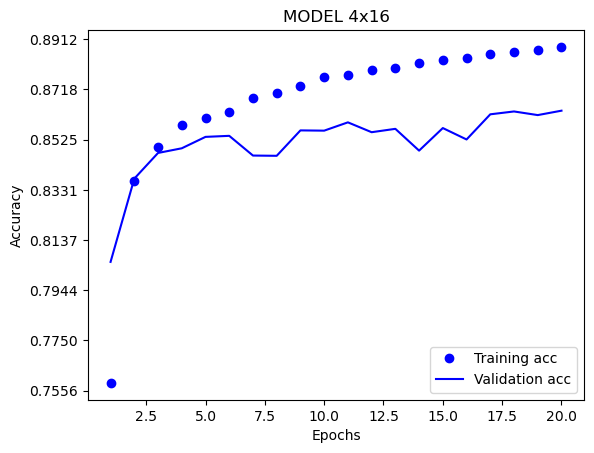

In [8]:
filename = "model2.weights.h5"
history = model_4x16.fit(train_images, train_labels, epochs=EPOCHS, verbose=VERBOSE, validation_data = (test_images, test_labels))
history_dict = history.history
utils.hist_plot(history_dict, "MODEL 4x16")
#model_4x16.save_weights(filename)